# Phase 2 demo: classical forecasting of daily AQI

One city end to end, using the project's own modules (the same code the full evaluation runs):

1. Load and preprocess the daily AQI series
2. Stationarity tests (ADF, KPSS), decomposition, ACF / PACF
3. Fit ARIMA, SARIMA (+ annual Fourier terms) and Holt-Winters, orders chosen by AIC
4. Residual diagnostics (Ljung-Box, Jarque-Bera)
5. 30-day forecast on the final hold-out (2 Jun - 1 Jul 2020), RMSE / MSE / MAE / MAPE against naive baselines
6. Results over all six rolling windows (from `python -m src.run_forecasting`)

Change `CITY` below to run another city (Delhi, Bengaluru, Chennai, Hyderabad, Lucknow, Ahmedabad). Runs in about a minute.

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

from src.data_loader import load_all_cities
from src.preprocessing import TEST_DAYS, stationarity_report, to_model_space, from_model_space
from src.models.statistical import fit_arima, fit_sarima, fit_holt_winters, predict_sarima
from src.models.baselines import BASELINES
from src.evaluation import forecast_metrics
from src.phase2 import arima_aic_grid, residual_tests

warnings.filterwarnings("ignore")  # after the imports: statsmodels resets its own filters on import
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.precision", 3)

CITY = "Delhi"

## 1. Data and preprocessing

Daily CPCB AQI, regular daily index, gaps of up to 21 days time-interpolated (flagged, never scored). Models work on log(1 + AQI).

Delhi: 2015-01-01 to 2020-07-01, 2009 days, 10 interpolated (0.5%)


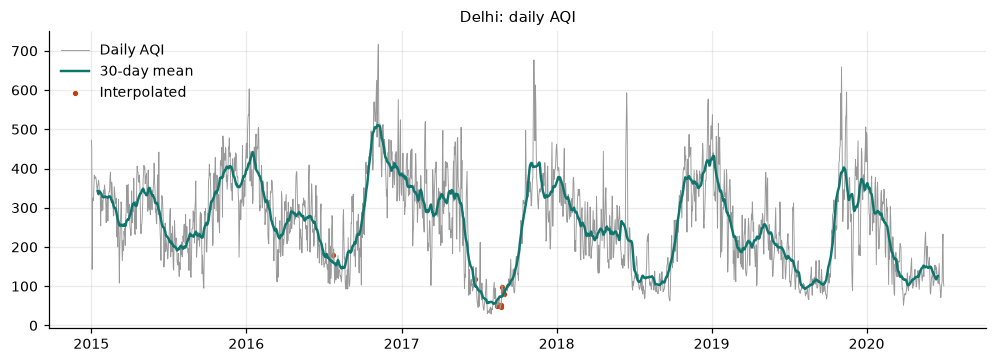

,value,is_interpolated
date,,
2015-01-01,472.0,False
2015-01-02,454.0,False
2015-01-03,143.0,False
2015-01-04,319.0,False
2015-01-05,325.0,False


In [2]:
df = load_all_cities([CITY])[CITY]
print(f"{CITY}: {df.index.min().date()} to {df.index.max().date()}, {len(df)} days, "
      f"{df['is_interpolated'].sum()} interpolated ({df['is_interpolated'].mean():.1%})")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df.index, df["value"], lw=0.6, color="0.6", label="Daily AQI")
ax.plot(df.index, df["value"].rolling(30, center=True).mean(), lw=1.6, color="#0f766e", label="30-day mean")
ax.scatter(df.index[df["is_interpolated"]], df.loc[df["is_interpolated"], "value"], s=6, color="#c2410c", label="Interpolated")
ax.set_title(f"{CITY}: daily AQI"); ax.legend(); plt.show()
df.head()

## 2. Stationarity, decomposition, autocorrelation

Tests run on the training part of the final hold-out (everything before the last 30 days), in log space.

In [3]:
train, test = df.iloc[:-TEST_DAYS], df.iloc[-TEST_DAYS:]
y = to_model_space(train["value"])

st = stationarity_report(y)
pd.DataFrame({
    "ADF stat": [st["adf_stat"], st["diff_adf_stat"]], "ADF p": [st["adf_p"], st["diff_adf_p"]],
    "KPSS stat": [st["kpss_stat"], st["diff_kpss_stat"]], "KPSS p": [st["kpss_p"], st["diff_kpss_p"]],
}, index=["log AQI (level)", "first difference"])

,ADF stat,ADF p,KPSS stat,KPSS p
log AQI (level),-3.431,9.952e-03,0.756,0.01
first difference,-17.577,4.027e-30,0.027,0.10


ADF says stationary: True | KPSS says stationary: False | differencing order used d = 0


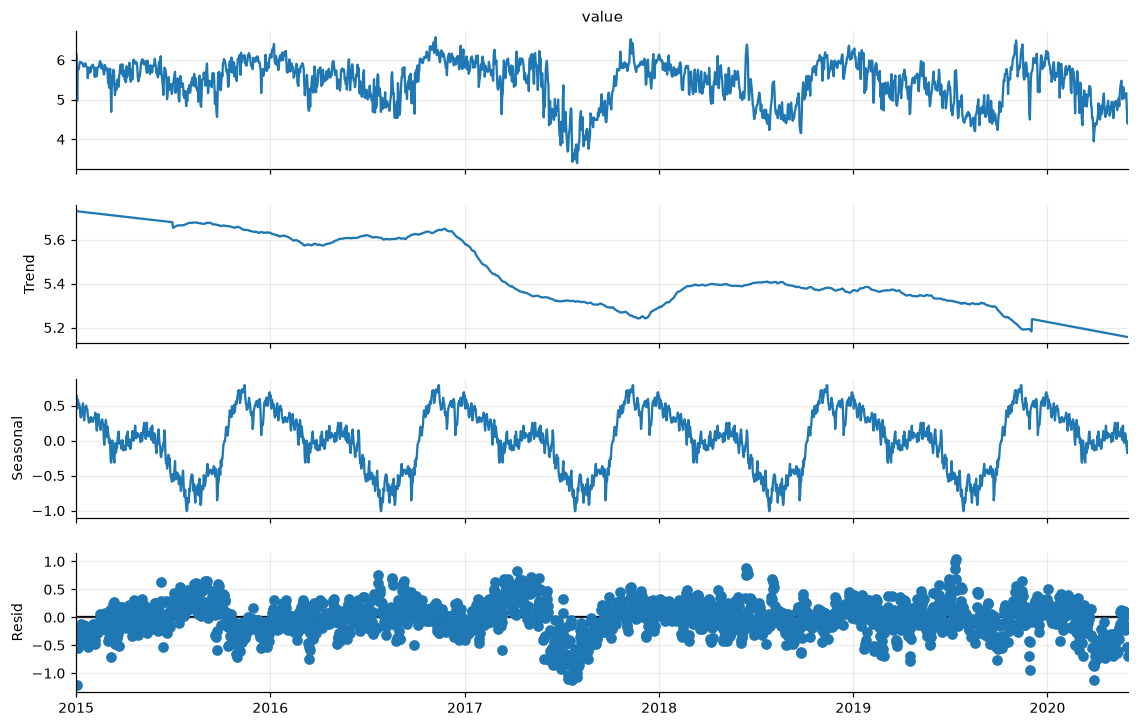

In [4]:
print("ADF says stationary:", st["adf_says_stationary"], "| KPSS says stationary:", st["kpss_says_stationary"],
      "| differencing order used d =", st["recommended_d"])
res = seasonal_decompose(y, model="additive", period=365, extrapolate_trend="period")
res.plot().set_size_inches(11, 7); plt.show()

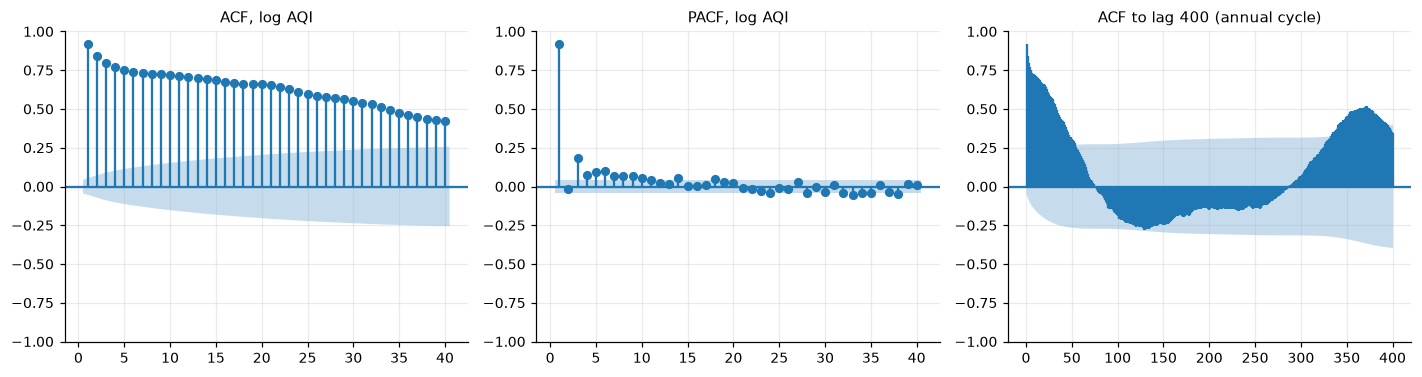

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
plot_acf(y, lags=40, ax=axes[0], zero=False, title="ACF, log AQI")
plot_pacf(y, lags=40, ax=axes[1], zero=False, method="ywm", title="PACF, log AQI")
plot_acf(y, lags=400, ax=axes[2], zero=False, marker=None, title="ACF to lag 400 (annual cycle)")
plt.tight_layout(); plt.show()

## 3. Fit the classical models

- **ARIMA**: d from the ADF test, (p, q) ≤ 3 by AIC
- **SARIMA**: (p, q) ≤ 2, weekly seasonal (P, Q) by AIC, plus 3 pairs of annual Fourier terms
- **Holt-Winters**: damped additive trend, seasonal period 7 or 365 by AIC

In [6]:
grid = arima_aic_grid(y, st["recommended_d"])
print("ARIMA AIC grid (rows p, columns q), difference from the best:")
display((grid - grid.min().min()).round(1))

arima, arima_cfg = fit_arima(y)
sarima, sarima_cfg = fit_sarima(y)
hw, hw_cfg = fit_holt_winters(y)
for cfg, m in [(arima_cfg, arima), (sarima_cfg, sarima), (hw_cfg, hw)]:
    print(f"{cfg:<60} AIC {m.aic:9.1f}")
print("Holt-Winters parameters:", {k: round(float(hw.params[k]), 3) for k in
      ("smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend")})

ARIMA AIC grid (rows p, columns q), difference from the best:


q,0,1,2,3
p,,,,
0,3837.0,2036.0,1237.5,887.6
1,145.2,146.8,59.6,19.4
2,147.0,136.3,0.0,2.0
3,84.9,3.2,NaN,3.9


ARIMA(2, 0, 2)                                               AIC    -650.5
SARIMA(2, 0, 2)x(0, 0, 1, 7) + 3 annual Fourier pairs        AIC    -668.8
Holt-Winters (add. damped trend, add. seasonal m=7)          AIC   -6003.5
Holt-Winters parameters: {'smoothing_level': 0.935, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.006, 'damping_trend': 0.8}


## 4. Residual diagnostics

Ljung-Box (H₀: no autocorrelation left) and Jarque-Bera (H₀: normal residuals), after a 14-day burn-in.

In [7]:
diag = pd.DataFrame({name: residual_tests(m.resid) for name, m in
                     [("ARIMA", arima), ("SARIMA", sarima), ("Holt-Winters", hw)]}).T
diag[["resid_mean", "resid_std", "lb7_p", "lb14_p", "jb_p", "skew", "kurtosis"]]

,resid_mean,resid_std,lb7_p,lb14_p,jb_p,skew,kurtosis
ARIMA,-1.309e-03,0.203,8.586e-01,9.331e-01,4.409e-50,-0.303,4.552
SARIMA,1.044e-04,0.202,2.719e-01,4.834e-01,3.334e-47,-0.263,4.529
Holt-Winters,-6.988e-04,0.216,1.237e-25,2.165e-22,6.993e-53,-0.106,4.700


## 5. 30-day forecast on the final hold-out

Scored on the AQI scale, observed (not interpolated) days only.

In [8]:
H = len(test)
to_aqi = lambda f: np.clip(from_model_space(np.asarray(f, dtype=float)), 0, None)
forecasts = {name: to_aqi(fn(y, H)) for name, fn in BASELINES.items()}
forecasts["ARIMA"] = to_aqi(arima.forecast(H))
forecasts["SARIMA"] = to_aqi(predict_sarima(sarima, y.index[-1], H))
forecasts["Holt-Winters"] = to_aqi(hw.forecast(H))

observed = ~test["is_interpolated"].to_numpy()
scores = pd.DataFrame({n: forecast_metrics(test["value"], f, mask=observed) for n, f in forecasts.items()}).T
scores = scores[["rmse", "mse", "mae", "mape"]].sort_values("rmse")
scores

,rmse,mse,mae,mape
ARIMA,35.723,1276.111,28.369,25.657
SARIMA,38.510,1483.028,31.014,28.075
Naive (last value),41.058,1685.767,29.633,20.843
Holt-Winters,41.612,1731.574,30.272,21.395
Seasonal naive (weekly),52.779,2785.667,41.667,34.646
Seasonal naive (annual),77.894,6067.433,67.833,58.055


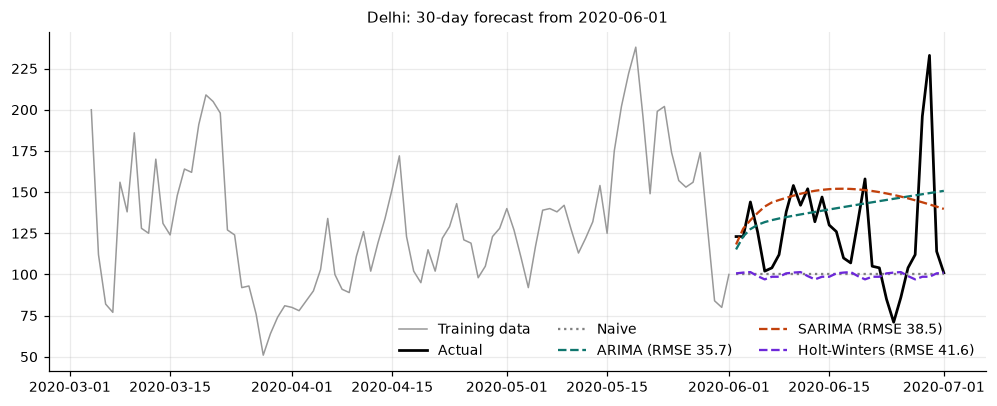

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
hist = df["value"].iloc[-TEST_DAYS - 90:-TEST_DAYS]
ax.plot(hist.index, hist, color="0.6", lw=1, label="Training data")
ax.plot(test.index, test["value"], color="k", lw=1.8, label="Actual")
ax.plot(test.index, forecasts["Naive (last value)"], ":", color="0.5", label="Naive")
for name, c in [("ARIMA", "#0f766e"), ("SARIMA", "#c2410c"), ("Holt-Winters", "#6d28d9")]:
    ax.plot(test.index, forecasts[name], "--", color=c, label=f"{name} (RMSE {scores.loc[name, 'rmse']:.1f})")
ax.set_title(f"{CITY}: 30-day forecast from {train.index[-1].date()}"); ax.legend(ncol=3); plt.show()

## 6. All six rolling windows

One hold-out month can mislead (June is a calm monsoon month), so models are compared on six 30-day windows across seasons. These come from `python -m src.run_forecasting`.

In [10]:
m = pd.read_csv("reports/forecasting/metrics.csv")
keep = list(BASELINES) + ["ARIMA", "SARIMA", "Holt-Winters"]
m = m[(m["city"] == CITY) & m["model"].isin(keep)]
display(m.pivot_table(index="model", columns="test_end", values="rmse").loc[keep].round(1))
summary = m.groupby("model")[["rmse", "mae", "mape"]].mean().loc[keep].sort_values("rmse").round(2)
best_baseline = summary.loc[list(BASELINES), "rmse"].min()
summary["vs best baseline %"] = (100 * (summary["rmse"] / best_baseline - 1)).round(1)
summary

test_end,2018-11-09,2019-03-09,2019-07-07,2019-11-04,2020-03-03,2020-07-01
model,,,,,,
Naive (last value),112.5,69.8,53.0,246.3,70.7,41.1
Seasonal naive (weekly),130.5,134.7,77.8,255.0,88.5,52.8
Seasonal naive (annual),89.5,110.7,145.4,103.3,87.0,77.9
ARIMA,149.2,87.8,62.3,236.7,70.0,35.7
SARIMA,56.4,80.8,45.3,126.4,67.8,38.5
Holt-Winters,114.0,71.8,53.4,245.2,69.5,41.6


,rmse,mae,mape,vs best baseline %
model,,,,
SARIMA,69.21,55.88,26.17,-30.0
Naive (last value),98.91,82.04,32.28,0.0
Holt-Winters,99.26,82.66,32.78,0.4
Seasonal naive (annual),102.29,78.46,40.18,3.4
ARIMA,106.95,91.06,37.78,8.1
Seasonal naive (weekly),123.22,103.22,45.23,24.6


## Interpretation

- Log AQI has no unit root (ADF), but its mean moves with the seasons (KPSS), so the annual cycle is modelled explicitly instead of differenced away.
- The ACF shows strong day-to-day persistence (AR terms) and an annual wave (Fourier terms); the weekly effect is weak.
- ARIMA/SARIMA residuals are close to white noise; Holt-Winters leaves autocorrelation. All residuals are heavy-tailed: pollution episodes are spikes no model sees coming.
- Over the six windows the best classical model beats every naive baseline; the full comparison for all cities is in `reports/phase2/tables.md`.